# Counting Barnacles: DALI Data Challenge

Scientists count every barnacle inside a wire frame by hand, often over 1,000
per photo. This notebook builds and evaluates a system that **proposes one dot
per barnacle**, so a person can check and correct dots instead of counting from
zero.

**Where things ended up:**

| | Result |
|---|---|
| Held-out half of img1 (scenes like the unseen photos) | count within **2.5–3.3%**, F1 **0.78–0.84** |
| Held-out half of img2 (dark, very different scene) | **~3× overcount**, F1 0.43–0.44 |
| Train on one photo, test on the other | fails badly (F1 0.08–0.25) |
| unseen_img1 / unseen_img2 | **1,482** / **194** barnacles |

The notebook follows the challenge's steps: idea → subtasks → data → building
each piece (with what failed) → evaluation → conclusions. The full day-by-day
reasoning, including every dead end, is in `LOG.md`. All code lives in `src/`;
this notebook only calls it.

*The slow experiments (training random forests) are cached in
`outputs/cache/`. The first run takes a few minutes on a laptop; later runs
are fast. Delete that folder to recompute everything from scratch.*

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline
%config InlineBackend.figure_format = "jpeg"
import sys; sys.path.insert(0, "..")

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import data, detect, evaluate, experiments, features, frame, pipeline

plt.rcParams.update({"figure.dpi": 80, "axes.titlesize": 11})
pd.set_option("display.precision", 2)

## 1. The idea and the subtasks

**Idea:** a semi-automated counter. The system crops the photo to the frame,
predicts where every barnacle is, and shows the dots to a scientist, who fixes
the few mistakes. Corrected photos can become new training data.

Each subtask has a clear input and output, so each can be built and tested on
its own:

| Subtask | Input | Output | Code |
|---|---|---|---|
| Ground truth | hand-drawn outline mask | one (x, y) dot per barnacle | `data.py` |
| Frame cropping | raw photo | straightened image of the frame's biggest rectangle | `frame.py` |
| Detection | cropped image | one dot per predicted barnacle | `features.py`, `detect.py` |
| Evaluation | predicted + true dots | count error, precision, recall, F1, plots | `evaluate.py` |

The core trick: **if every barnacle becomes a dot, counting is trivial**, and
evaluation is just comparing my dots with the scientists' dots.

## 2. The data

Two labeled photos (img1, img2) with hand-drawn outline masks, and two
unlabeled photos to count.

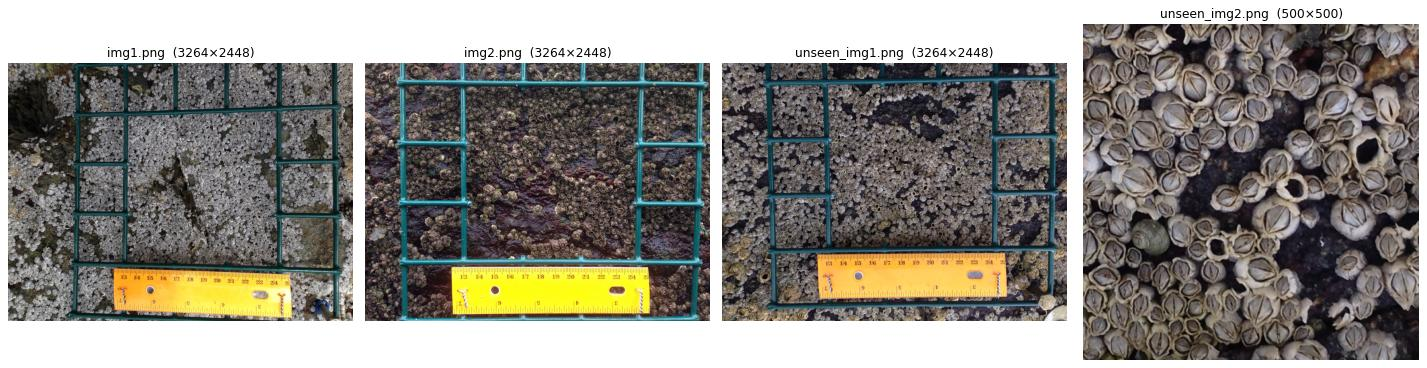

In [2]:
names = ["img1.png", "img2.png", "unseen_img1.png", "unseen_img2.png"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, n in zip(axes, names):
    im = data.load_image(n)
    ax.imshow(im); ax.set_title(f"{n}  ({im.shape[1]}×{im.shape[0]})"); ax.axis("off")
plt.tight_layout(); plt.show()

**First observations:**

* **img1 and img2 are very different scenes.** img1 has pale barnacles packed
  tightly on light rock; img2 has sparse brown barnacles on wet, dark red rock.
  That difference turns out to be the biggest challenge of the project.
* **The unseen photos look much more like img1** than img2.
* **unseen_img2 is small (500×500) and has no frame.** Section 5 shows where it
  came from.

**What did the scientists outline?** Zooming into the provided overlay shows
each outline traces the barnacle's **central plates (the operculum)**, not the
whole white shell, and that **empty shells (dead barnacles) are not outlined**:

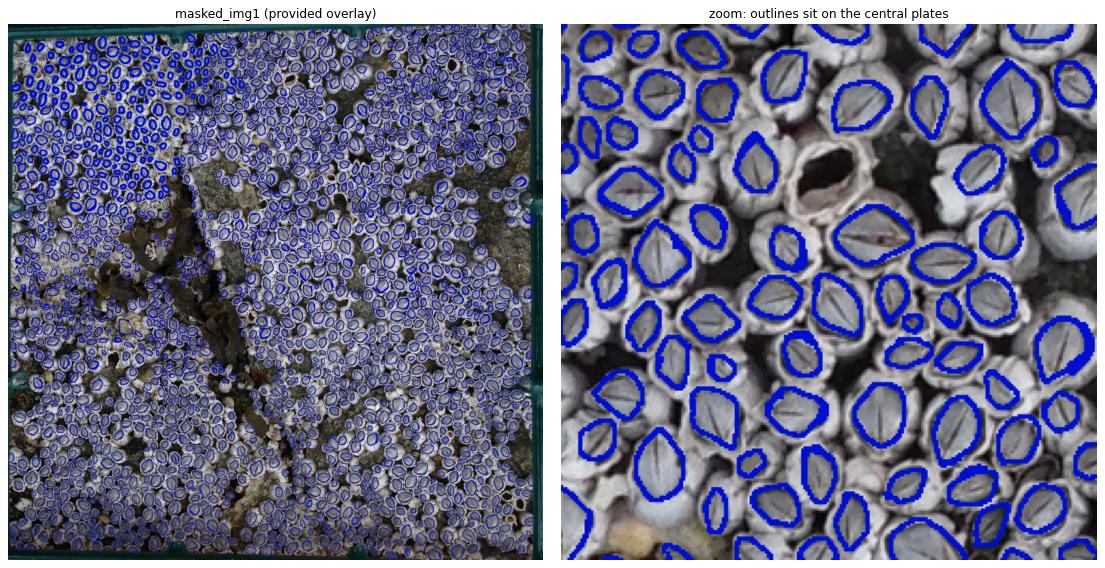

In [3]:
overlay = data.load_image("masked_img1.png")
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].imshow(overlay); axes[0].set_title("masked_img1 (provided overlay)")
axes[1].imshow(overlay[80:330, 640:890]); axes[1].set_title("zoom: outlines sit on the central plates")
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

Near the top center of the zoom there's an **empty shell with no outline**.
So the real target is **live barnacles with visible plates**. That makes the
task harder: a detector has to tell a live barnacle from an empty shell that
looks very similar.

## 3. Ground truth: from messy outlines to one dot per barnacle

Every metric depends on this step, so I spent the most time here. The masks
are RGBA PNGs with a transparent white background, so line pixels are found by
transparency (alpha > 0), not color.

Up close, the masks have every kind of messiness:

* **gaps** in outlines
* **touching outlines** (never more than two at once)
* **"bubbles":** 1–2 px holes *inside* a drawn line, which must not count as barnacles
* **floating pixels**
* two that only showed up on real data: **stroke thickness that varies within
  one mask**, and **tiny loops where the pen overlapped itself**

**How the final version works** (`data.mask_to_regions`), for each connected
cluster of line pixels:

1. Skip specks.
2. Cut the cluster out on its own canvas, so gap-closing can never fuse it with
   a neighbor.
3. Count its **real holes**: one closed barnacle per hole, ignoring bubbles.
   Two touching outlines are one cluster but two holes.
4. Give each stroke pixel to its nearest hole, using this cluster's own line
   width.
5. Line pixels nobody claims form an outline that never closed, so it's
   repaired with its convex hull.
6. Drop shapes smaller than 15% of a typical barnacle.

It took five versions to get here (see `LOG.md` §1). The two most instructive
failures:

* **Global gap-closing fused neighbors:** 70 packed test circles became 7 dots.
* **Gap-closing also erased small barnacles.** The table at the end of this
  section measures that trade-off directly.

In [4]:
rows = []
for n in (1, 2):
    _, dots, areas, repaired, det = data.mask_to_regions(f"mask{n}.png", return_details=True)
    rows.append({"mask": f"mask{n}", "barnacles": len(dots), **det})
pd.DataFrame(rows).set_index("mask").T

mask,mask1,mask2
barnacles,1733,398
specks,29,124
ignored_small_holes,395,983
gap_closed,17,1
closed,1719,398
repaired,14,0
split_merged_arcs,0,0
dropped_overlapping_arcs,0,1
dropped_too_small,7,22
dropped_too_large,0,0


How to read this:

* **Bubbles are everywhere:** nearly 1,000 in mask2. Without the bubble
  filter, mask2's count would roughly double.
* **Only 14 of mask1's 1,733 barnacles needed hull repair**, and none of mask2's.
* **The size filter dropped 7 and 22 shapes.** I checked every one by eye; all
  were pen-overlap loops or slivers.

Here are the hard cases on the real masks:

* **black** = drawn line
* **light blue** = area assigned to a barnacle
* **magenta** = line pixels assigned to no barnacle
* **red dot** = closed outline
* **orange dot** = repaired with the convex hull

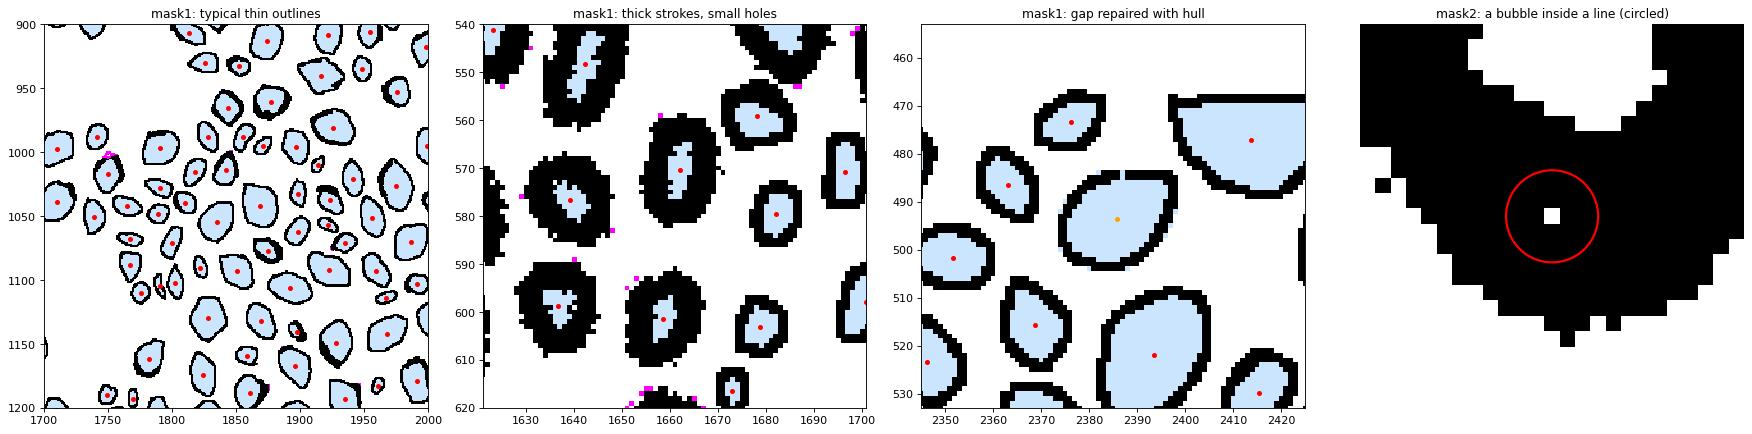

In [5]:
lines1, lines2 = data.load_mask_lines("mask1.png"), data.load_mask_lines("mask2.png")
reg1, dots1, areas1, rep1 = data.mask_to_regions("mask1.png")
reg2, dots2, areas2, rep2 = data.mask_to_regions("mask2.png")
rx, ry = dots1[rep1][0].astype(int)  # first hull-repaired barnacle

panels = [
    (lines1, reg1, dots1, rep1, (1700, 2000, 900, 1200), "mask1: typical thin outlines"),
    (lines1, reg1, dots1, rep1, (1621, 1701, 540, 620), "mask1: thick strokes, small holes"),
    (lines1, reg1, dots1, rep1, (rx - 40, rx + 40, ry - 40, ry + 40), "mask1: gap repaired with hull"),
]
# find a real "bubble": a hole inside a stroke, too small to be a barnacle
cs, hier = cv2.findContours(lines2.astype(np.uint8), cv2.RETR_CCOMP, cv2.CHAIN_APPROX_NONE)
def well_inside(c):  # hole surrounded by stroke on all sides, not a notch at its edge
    x, y = c.reshape(-1, 2).mean(axis=0).astype(int)
    return lines2[y - 3:y + 4, x - 3:x + 4].sum() >= 44
bubble = next(c for c, h in zip(cs, hier[0]) if h[3] != -1 and cv2.contourArea(c) < 5 and well_inside(c))
qx, qy = bubble.reshape(-1, 2).mean(axis=0).astype(int)

fig, axes = plt.subplots(1, 4, figsize=(22, 5.5))
for ax, (ln, rg, d, rp, z, title) in zip(axes, panels):
    evaluate.plot_mask_dots(ln, rg, d, rp, ax=ax, zoom=z, title=title)
    ax.get_legend().remove()
axes[3].imshow(lines2[qy - 12:qy + 13, qx - 12:qx + 13], cmap="gray_r", interpolation="nearest")
axes[3].add_patch(plt.Circle((12, 12), 3, fill=False, color="red", lw=2))
axes[3].set_title("mask2: a bubble inside a line (circled)"); axes[3].axis("off")
plt.tight_layout(); plt.show()

**The gap-closing trade-off, measured.** For every outline cluster in each mask,
I compared the number of real holes found with and without closing small
gaps. Closing *rescues* outlines with a gap, but it also *erases* small
barnacles whose interior is narrower than the closing kernel. That's why the
final code tries both versions and keeps whichever finds more holes.

In [6]:
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
rows = []
for n in (1, 2):
    lines = data.load_mask_lines(f"mask{n}.png").astype(np.uint8)
    k, labels, stats, _ = cv2.connectedComponentsWithStats(lines, connectivity=8)
    gained = lost = 0
    for i in range(1, k):
        x, y, w, h, size = stats[i]
        if size < 10:
            continue
        piece = np.pad((labels[y:y + h, x:x + w] == i).astype(np.uint8), 6)
        raw = data._find_holes(piece, 5)[1]
        closed = data._find_holes(cv2.morphologyEx(piece, cv2.MORPH_CLOSE, kernel), 5)[1]
        gained += closed > raw
        lost += closed < raw
    rows.append({"mask": f"mask{n}", "closing rescues a gapped outline": gained,
                 "closing erases a small barnacle": lost})
pd.DataFrame(rows).set_index("mask")

,closing rescues a gapped outline,closing erases a small barnacle
mask,,
mask1,17,100
mask2,1,4


**Size and spacing of the labeled barnacles.** These numbers set parameters
later, so those parameters come from data rather than guesses:

* **Typical radius** sets the matching radius in evaluation: a predicted dot
  counts as correct within half a typical diameter.
* **The smallest typical radius** sets the minimum spacing between predicted dots.
* **The radius range** set the kernel sizes (σ up to 16 px).

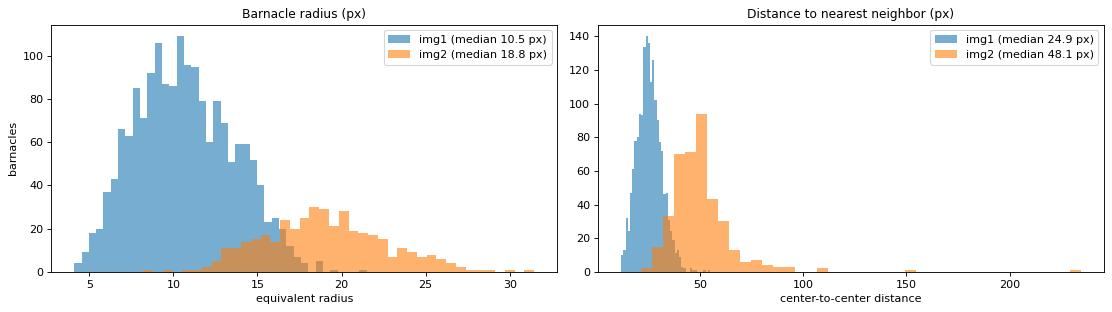

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for n, d, a in [(1, dots1, areas1), (2, dots2, areas2)]:
    st = data.barnacle_stats(d, a)
    axes[0].hist(st["diameter"] / 2, bins=40, alpha=0.6, label=f"img{n} (median {np.median(st['diameter']) / 2:.1f} px)")
    axes[1].hist(st["nn_distance"], bins=40, alpha=0.6, label=f"img{n} (median {np.median(st['nn_distance']):.1f} px)")
axes[0].set(title="Barnacle radius (px)", xlabel="equivalent radius", ylabel="barnacles")
axes[1].set(title="Distance to nearest neighbor (px)", xlabel="center-to-center distance")
for a in axes: a.legend()
plt.tight_layout(); plt.show()

img2's barnacles are about **twice as big and twice as far apart** as img1's.
Remember this; it matters in sections 9 and 10.

## 4. Finding the frame

The frame is a grid of rectangles; only the biggest one is counted. The
biggest rectangle is the **largest region completely enclosed by wire**, so:

1. find wire pixels by color;
2. find all enclosed holes with `findContours`, and take the largest;
3. simplify it to 4 corners;
4. perspective-warp it into a straight-on square. Photos aren't taken
   perfectly straight down, so a bounding box would include rock outside the frame.

**First attempt: complete failure.** I guessed the usual "green" hue range
(35–90 on OpenCV's 0–179 scale), and the largest "hole" was a few pixels wide.
Measuring the wire's actual color showed why: the wire is **teal**.

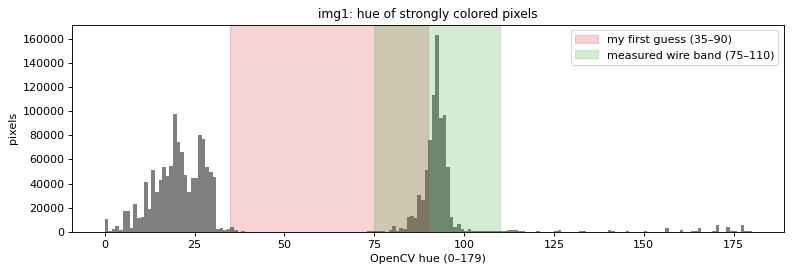

In [8]:
hsv = cv2.cvtColor(data.load_image("img1.png"), cv2.COLOR_RGB2HSV)
vivid = hsv[..., 1] > 80  # strongly colored pixels only
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.hist(hsv[..., 0][vivid], bins=180, range=(0, 180), color="gray")
ax.axvspan(35, 90, color="tab:red", alpha=0.2, label="my first guess (35–90)")
ax.axvspan(75, 110, color="tab:green", alpha=0.2, label="measured wire band (75–110)")
ax.set(title="img1: hue of strongly colored pixels", xlabel="OpenCV hue (0–179)", ylabel="pixels")
ax.legend(); plt.tight_layout(); plt.show()

The wire's hue peaks at about 92, just outside my guessed band. (The other
peak, near 20, is the orange ruler and brownish rock.) The wire is
also very dark in img1's shade, with brightness as low as 31, below my
original minimum of 40. With the measured thresholds, frame detection works
on every framed photo. If no large enclosed region exists, the whole photo is
used (unseen_img2):

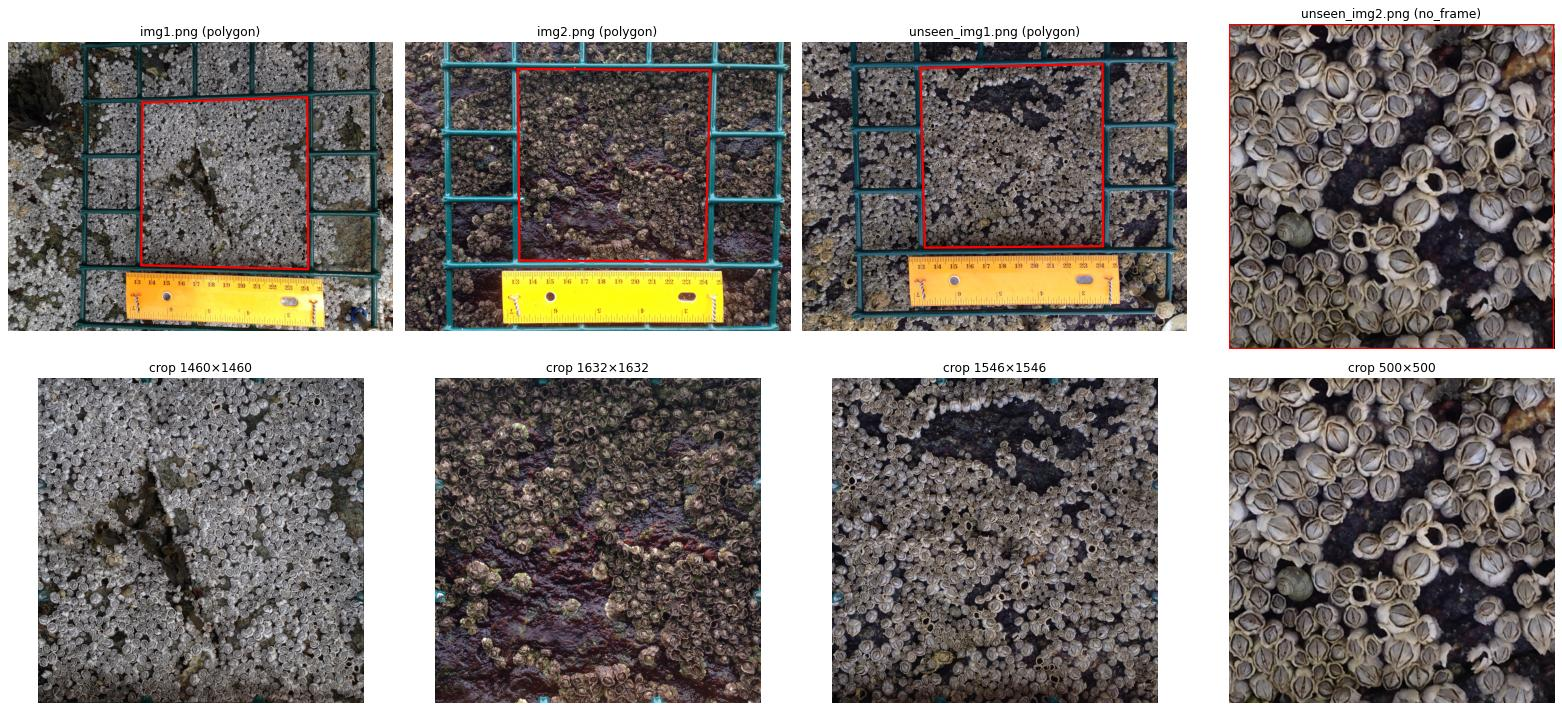

img1: 1733 of 1733 labeled barnacles fall inside the detected crop
img2: 398 of 398 labeled barnacles fall inside the detected crop


In [9]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for k, n in enumerate(names):
    im = data.load_image(n); fr = frame.crop_to_frame(im)
    c = np.vstack([fr["corners"], fr["corners"][:1]])
    axes[0, k].imshow(im); axes[0, k].plot(c[:, 0], c[:, 1], "r-", lw=2)
    axes[0, k].set_title(f"{n} ({fr['method']})")
    axes[1, k].imshow(fr["crop"]); axes[1, k].set_title(f"crop {fr['shape'][1]}×{fr['shape'][0]}")
    for a in axes[:, k]: a.axis("off")
plt.tight_layout(); plt.show()

for n in (1, 2):
    fr = frame.crop_to_frame(data.load_image(f"img{n}.png"))
    _, d, _, _ = data.mask_to_regions(f"mask{n}.png")
    print(f"img{n}: {len(frame.warp_dots(d, fr['M'], fr['shape']))} of {len(d)} labeled barnacles fall inside the detected crop")

Every labeled barnacle lands inside the detected crop. The crop sizes also
roughly match the provided `masked_img` crops (1460 vs 1449 px for img1).
Together, that's strong evidence the corners are right.

## 5. A detour: is unseen_img2 zoomed in?

unseen_img2's barnacles *looked* about twice as big as the others'. A model
that learned "barnacles are this many pixels wide" would struggle on a zoomed
photo, and without a frame there's no built-in ruler. So I tried two ways to
estimate barnacle size from image content alone, and **both failed**:

* **Blob kernels at many sizes, picking the strongest:** always picked the
  smallest size tried, even though img1's and img2's barnacles differ almost
  2× in size. Fine rock texture dominates.
* **Autocorrelation width:** the estimate changed 6× depending on one filter
  setting. It measured my filter, not the barnacles.

Then I asked the basic question I should have started with: *where did this
photo come from?*

best match score 1.000 at x=1500, y=1000 (1.000 = identical pixels)


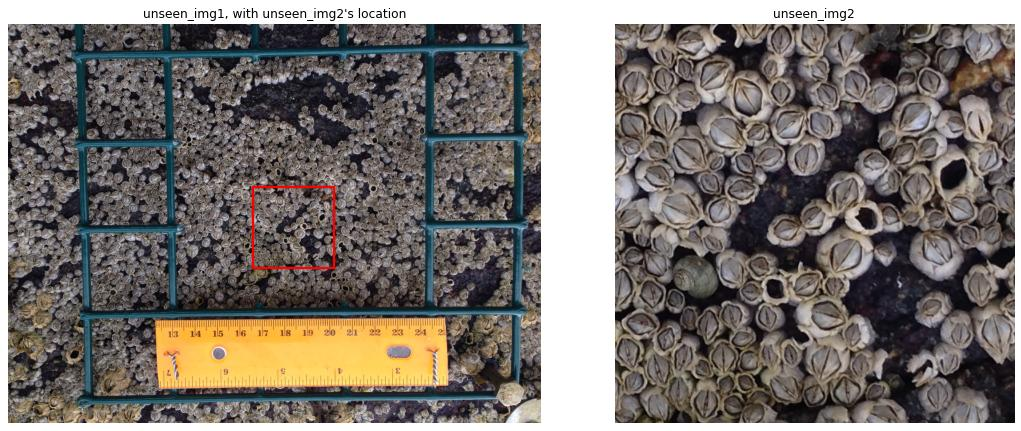

In [10]:
big = data.load_image("unseen_img1.png"); small = data.load_image("unseen_img2.png")
score = cv2.matchTemplate(cv2.cvtColor(big, cv2.COLOR_RGB2GRAY),
                          cv2.cvtColor(small, cv2.COLOR_RGB2GRAY), cv2.TM_CCOEFF_NORMED)
_, best, _, (bx, by) = cv2.minMaxLoc(score)
print(f"best match score {best:.3f} at x={bx}, y={by} (1.000 = identical pixels)")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
axes[0].imshow(big); axes[0].add_patch(plt.Rectangle((bx, by), 500, 500, fill=False, color="red", lw=2))
axes[0].set_title("unseen_img1, with unseen_img2's location")
axes[1].imshow(small); axes[1].set_title("unseen_img2")
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

**unseen_img2 is an exact, unscaled crop of unseen_img1.** It only looked zoomed
because it was displayed larger. There was no scale problem at all; two
experiments went into a problem that didn't exist.

The upside: since it's the same scene, the two counts should agree. With no
labels for the unseen photos, **that's the only check of the final model
available** (section 11).

## 6. Features: what the model sees

A single pixel's color can't say whether it's barnacle or pale rock; its
**neighborhood** can. So every pixel gets 17 numbers from kernels at 5 scales
(σ = 1, 2, 4, 8, 16 px):

* **smooth:** Gaussian blur. How bright is it around here?
* **grad:** gradient magnitude. Is there an edge here?
* **log:** Laplacian of Gaussian. Is this the center of a blob about σ√2 px
  in radius?
* **lab_a, lab_b:** color tint, separate from brightness.

σ = 16 was added after the first real-data run, because img2's barnacles
(radius about 19 px) were bigger than anything σ = 8 responds to.

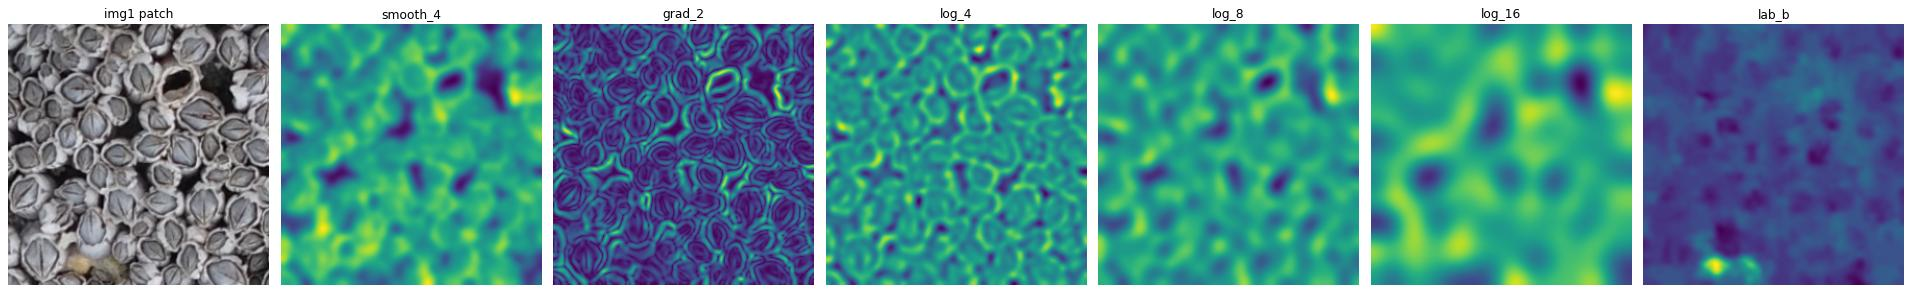

In [11]:
crop1 = frame.crop_to_frame(data.load_image("img1.png"))["crop"]
patch = crop1[80:330, 640:890]
F, fnames = features.compute_features(patch)
show = ["smooth_4", "grad_2", "log_4", "log_8", "log_16", "lab_b"]
fig, axes = plt.subplots(1, 7, figsize=(24, 3.8))
axes[0].imshow(patch); axes[0].set_title("img1 patch")
for ax, nm in zip(axes[1:], show):
    ax.imshow(F[..., fnames.index(nm)], cmap="viridis"); ax.set_title(nm)
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

Each kernel highlights something different: `grad_2` traces the edges of
plates and shells, while the blob detectors (`log_*`) respond to round shapes
at their own scale. No single map is a barnacle detector on its own.
**A random forest** then learns which combinations mean "barnacle pixel."
It's a good fit here: no feature scaling needed, it trains in seconds, and it
reports which features it relied on.

**Probability map to dots:**

1. Threshold at 0.5 and remove tiny blobs.
2. A distance transform turns each blob into a hill.
3. Each hilltop becomes one dot.

**Baseline for comparison:** a single blob kernel at one size, with its
threshold tuned on training data.

## 7. How I evaluate

* **Matching:** predicted and true dots are paired **one-to-one** (Hungarian
  algorithm) within half a typical barnacle diameter. Without one-to-one
  matching, a dot between two barnacles could "find" both.
* **Two kinds of metric:** **count error** is what the scientists record.
  **Precision / recall / F1** catch a lucky count where misses and false alarms
  cancel out.
* **Only two labeled photos**, so I ran two experiments that answer different
  questions:
  * **A. Cross-image:** train on one photo, test on the other. *Does it work
    on a completely different scene?*
  * **B. Spatial split:** train on the left half of both photos, test on the
    right halves, then swap. *Does it work on a new photo similar to the
    training photos?* That's the relevant question, since the unseen photos
    resemble img1.

The split leaves a **60 px buffer** between halves. The largest kernel looks
about 48 px around each pixel, so without a gap, test pixels near the middle
would share context with training pixels.

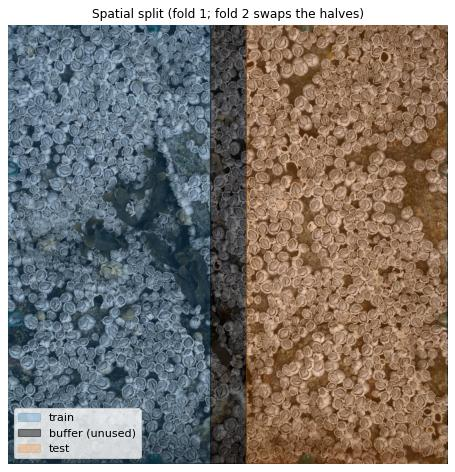

In [12]:
h, w = crop1.shape[:2]
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(crop1)
ax.add_patch(plt.Rectangle((0, 0), w // 2 - 60, h, color="tab:blue", alpha=0.25, label="train"))
ax.add_patch(plt.Rectangle((w // 2 - 60, 0), 120, h, color="black", alpha=0.45, label="buffer (unused)"))
ax.add_patch(plt.Rectangle((w // 2 + 60, 0), w - w // 2 - 60, h, color="tab:orange", alpha=0.25, label="test"))
ax.set_title("Spatial split (fold 1; fold 2 swaps the halves)"); ax.legend(loc="lower left"); ax.axis("off")
plt.tight_layout(); plt.show()

## 8. Experiment A: train on one photo, test on the other. Failed.

In [13]:
cross = experiments.cross_experiment()
pd.DataFrame(cross["rows"])

,trained_on,tested_on,n_pred,n_true,pct_count_error,precision,recall,f1
0,img1,img2,1633,398,310.30,0.16,0.65,0.26
1,img2,img1,434,1733,-74.96,0.18,0.05,0.07


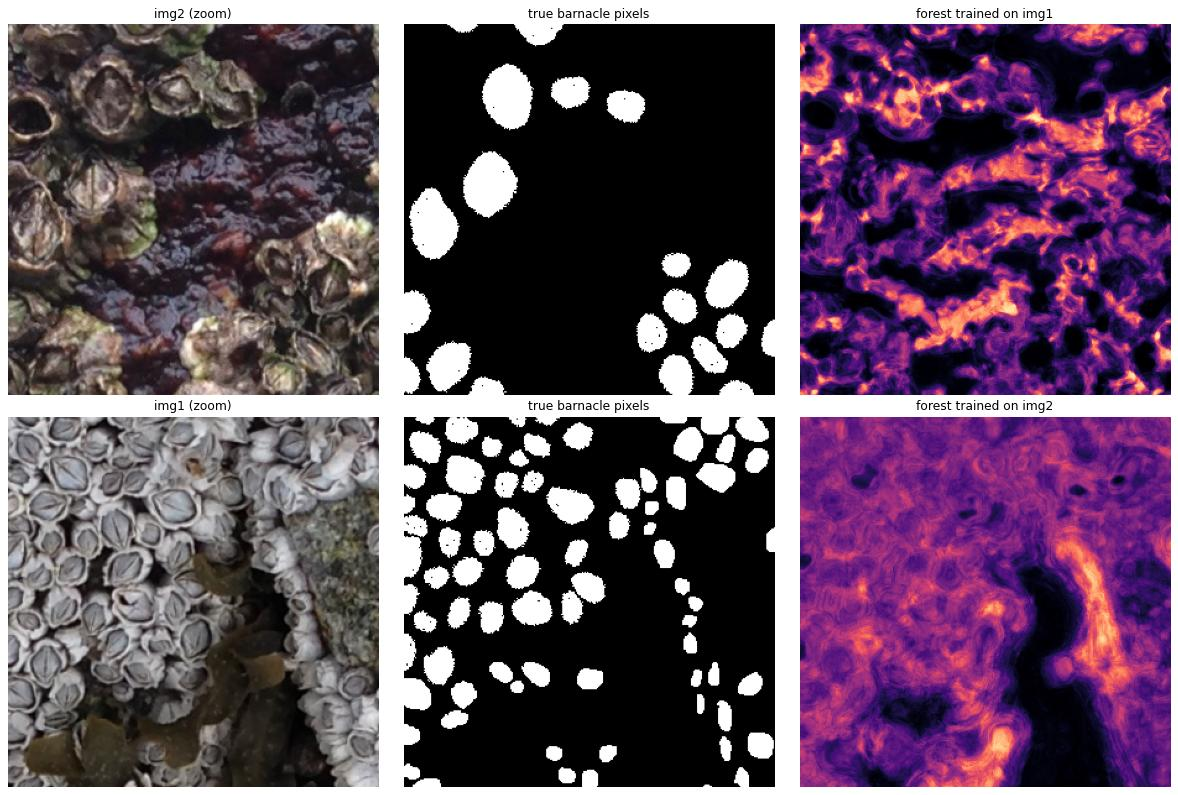

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for row, (tr, te) in enumerate([(1, 2), (2, 1)]):
    L = pipeline.load_labeled(te); z = (slice(300, 600), slice(300, 600))
    prob = cross["probs"][f"img{tr}->img{te}"].astype(np.float32)
    axes[row, 0].imshow(L["crop"][z]); axes[row, 0].set_title(f"img{te} (zoom)")
    axes[row, 1].imshow(L["fg"][z], cmap="gray"); axes[row, 1].set_title("true barnacle pixels")
    axes[row, 2].imshow(prob[z], cmap="magma", vmin=0, vmax=1); axes[row, 2].set_title(f"forest trained on img{tr}")
    for a in axes[row]: a.axis("off")
plt.tight_layout(); plt.show()

**Each model's count lands near its *training* photo's count.** Trained on
dense img1, it overcounts img2 by about 4×. Trained on sparse img2, it
undercounts img1 by about 70%. It learned "how dense barnacles are in my
photo," not "what a barnacle looks like."

The probability maps show it directly: trained on img1, the forest lights up
brown *rock* in img2; trained on img2, it produces a vague haze over img1.
With one example of each very different scene, nothing can learn what the
two have in common. **More varied labeled photos would be the single most
valuable improvement.**

## 9. Experiment B: spatial split. The main result.

In [15]:
split = experiments.split_experiment()
table = pd.DataFrame(split["rows"])
table.pivot_table(index=["image", "method"], columns="test_half",
                  values=["pct_count_error", "f1"]).round(2)

f1       pct_count_error        
test_half          L     R               L       R
image method                                      
img1  baseline  0.24  0.23          -56.90  -63.24
      forest    0.77  0.84            2.34    2.10
img2  baseline  0.39  0.50          135.95   35.91
      forest    0.45  0.43          196.08  195.45

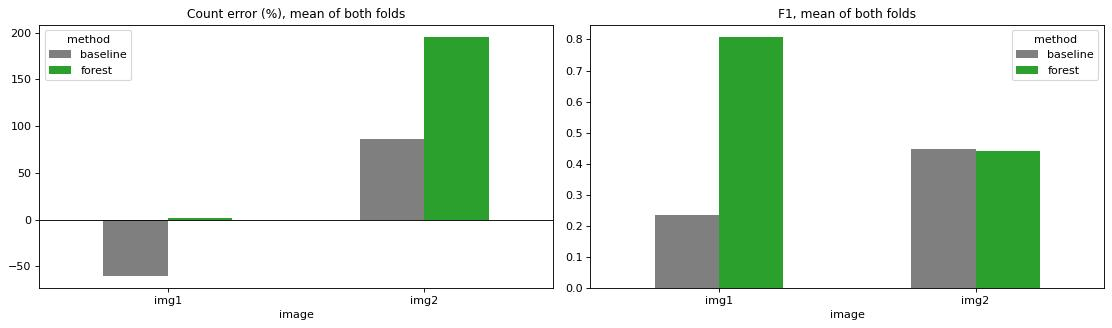

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, col, title in [(axes[0], "pct_count_error", "Count error (%)"), (axes[1], "f1", "F1")]:
    piv = table.groupby(["image", "method"])[col].mean().unstack()
    piv.plot.bar(ax=ax, rot=0, color=["tab:gray", "tab:green"])
    ax.set_title(f"{title}, mean of both folds"); ax.axhline(0, color="k", lw=0.8)
plt.tight_layout(); plt.show()

**On img1, the forest is within 2.5–3.3% of the true count** and finds 79–86%
of barnacles in the right place, beating the baseline by a wide margin. The
baseline has to choose *one* barnacle size, and the tuned value (radius 14.7)
is a compromise between img1's barnacles (10.5) and img2's (18.8) that fits
neither.

**On img2, the forest overcounts about 3×.** It finds 85–90% of the real
barnacles (high recall), but only 29% of its dots are correct (low precision).
In one fold the plain baseline actually does better. Here's what the errors
look like:

* **green dot** = hit
* **red ×** = false alarm
* **blue circle** = miss

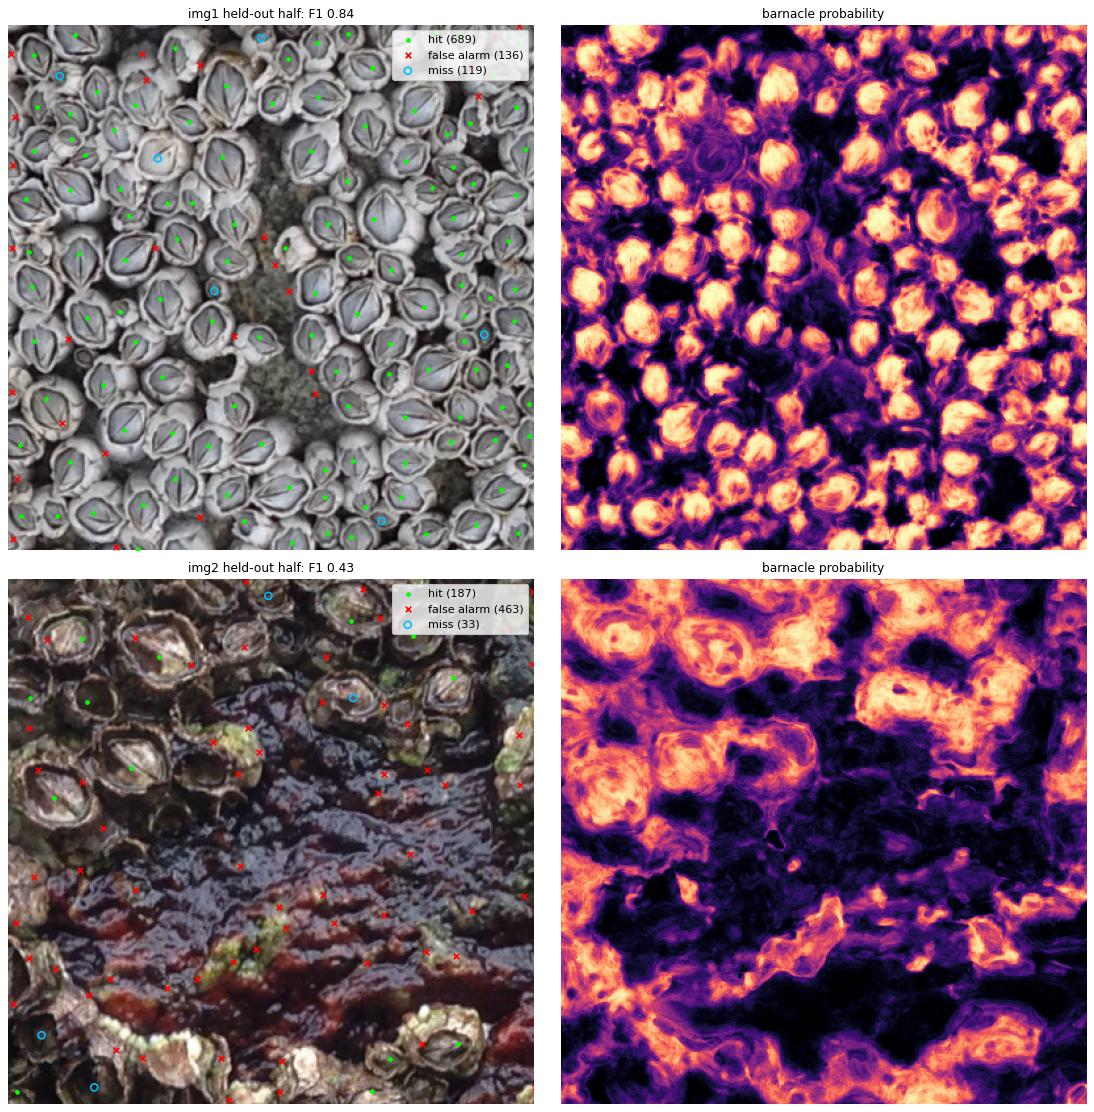

In [17]:
fold = split["folds"]["train_L"]
fig, axes = plt.subplots(2, 2, figsize=(14, 14))
for row, name in enumerate(["img1", "img2"]):
    im = fold["images"][name]; L = pipeline.load_labeled(int(name[-1]))
    x0 = L["crop"].shape[1] // 2 + 60; zoom = (x0, x0 + 400, 500, 900)
    evaluate.draw_overlay(L["crop"], im["dots"], im["gt"], im["result"], ax=axes[row, 0], zoom=zoom,
                          title=f"{name} held-out half: F1 {im['result']['f1']:.2f}")
    axes[row, 1].imshow(im["prob"].astype(np.float32), cmap="magma", vmin=0, vmax=1)
    axes[row, 1].set_xlim(zoom[0], zoom[1]); axes[row, 1].set_ylim(zoom[3], zoom[2])
    axes[row, 1].set_title("barnacle probability"); axes[row, 1].axis("off")
plt.tight_layout(); plt.show()

On img1, probability concentrates on the plates, and nearly every barnacle gets
one dot. On img2, probability spreads over **whole shells**, including empty ones,
and over patches of algae and wet rock, so blobs merge and get several dots
each.

**Where do errors happen?** Count error per tile of the held-out half.
On img1, tile errors range from −15 to +14 but mostly **cancel out**, so a
close overall count doesn't mean every region is right. On img2, **every
tile overcounts**: the error is systematic, not local. Each
cell shows the error, with the true count in parentheses. This is also how a
review tool could point a scientist to the tiles worth double-checking.

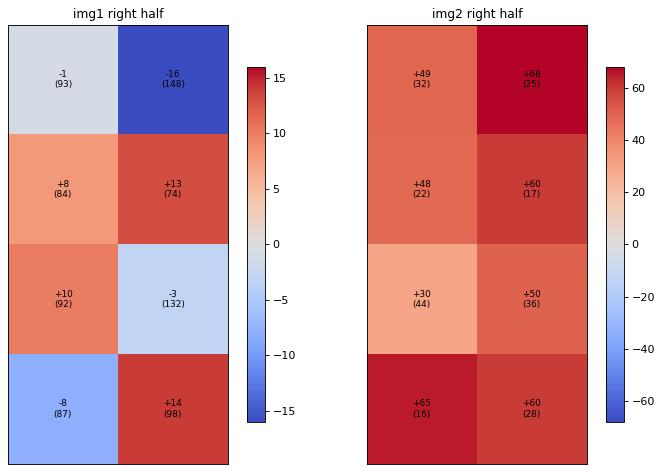

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(10, 6))
for ax, name in zip(axes, ["img1", "img2"]):
    im = fold["images"][name]; size = int(pipeline.load_labeled(int(name[-1]))["crop"].shape[0])
    pg, tg = evaluate.tile_counts(im["dots"], im["gt"], size, n_tiles=4)
    evaluate.plot_tile_errors(pg[:, 2:], tg[:, 2:], ax=ax, title=f"{name} right half")
plt.tight_layout(); plt.show()

**What the forest relied on** (feature importance, averaged over both folds).
The large-scale blob detector and color matter most: "a barnacle-sized blob of
the right tint."

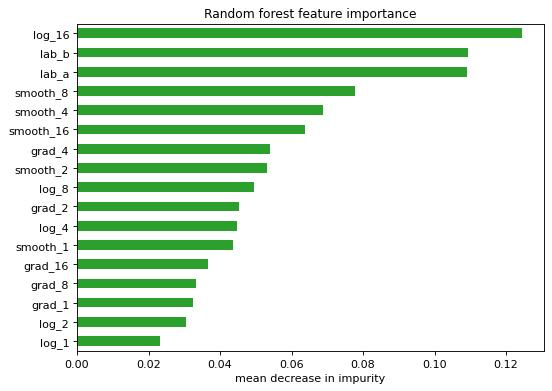

In [19]:
imp = pd.DataFrame([f["importances"] for f in split["folds"].values()]).mean().sort_values()
imp.plot.barh(figsize=(7, 5), color="tab:green", title="Random forest feature importance")
plt.xlabel("mean decrease in impurity"); plt.tight_layout(); plt.show()

## 10. Why img2 fails, and a fix that didn't work

img2's barnacles are about twice as big as img1's, while the minimum spacing
between dots comes from the *smallest* training barnacles (10.5 px). Could
wider spacing fix img2's overcount? This re-extracts dots from the same
probability maps at different spacings.

*(The sweep reuses cached half-precision probability maps, so its 10.5 px row
can differ from section 9 by a dot.)*

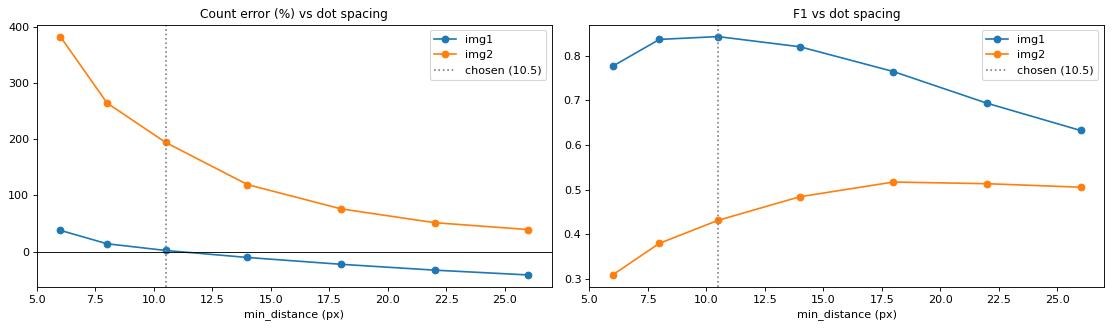

In [20]:
sweep = pd.DataFrame(experiments.spacing_sweep())
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for name, g in sweep.groupby("image"):
    axes[0].plot(g["min_distance"], g["pct_count_error"], "o-", label=name)
    axes[1].plot(g["min_distance"], g["f1"], "o-", label=name)
axes[0].axhline(0, color="k", lw=0.8)
axes[0].set(title="Count error (%) vs dot spacing", xlabel="min_distance (px)")
axes[1].set(title="F1 vs dot spacing", xlabel="min_distance (px)")
for a in axes: a.axvline(10.5, color="gray", ls=":", label="chosen (10.5)"); a.legend()
plt.tight_layout(); plt.show()

**No single spacing works for both.** Wider spacing cuts img2's overcount
(+199% → +45% at 26 px) but discards real barnacles in img1 (+3% → −42%).

I also tried estimating barnacle size per photo from the predicted blobs, with
no labels needed. It failed: img2's predicted blobs are *smaller* than img1's
(7.5 vs 12.4 px median radius), because they're fragments of shell rather than
whole plates.

**So img2's real problem isn't spacing. It's that the pixel classifier can't
tell plates from shells in that scene.** The next thing I'd try is a second
stage that judges *candidate dots* using neighborhood information a single
pixel can't see. I wrote it, but its nested experiment didn't fit my compute
budget, so I removed the untested code rather than ship it (`LOG.md` §4).

## 11. Counting the unseen photos

The final model trains on **all** of img1 and img2. This is the same code
`count_barnacles.py` runs.

In [21]:
final = experiments.final_counts()
pd.DataFrame([{"photo": k, "barnacles": v["count"], "frame": v["method"]} for k, v in final.items()]).set_index("photo")

,barnacles,frame
photo,,
unseen_img1,1509,polygon
unseen_img2,214,no_frame


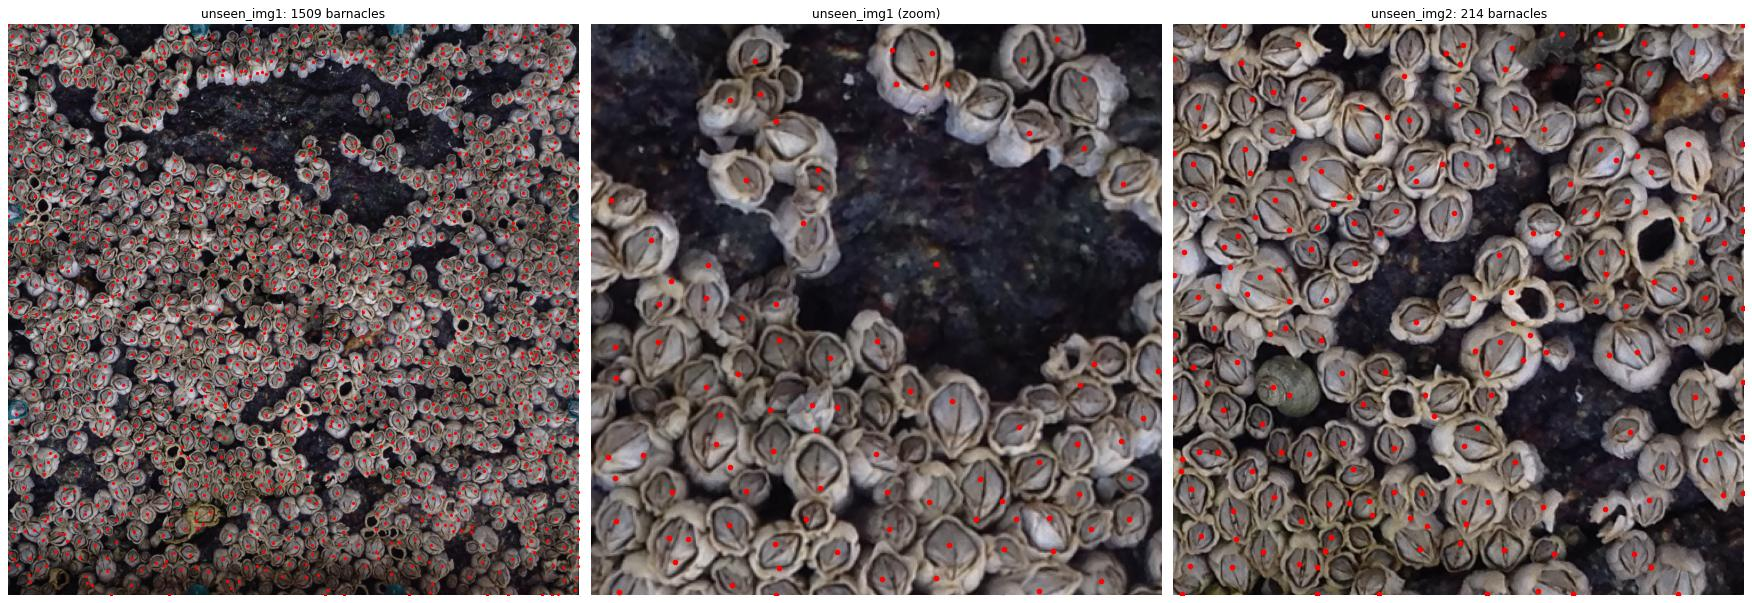

In [22]:
crop_u1 = frame.crop_to_frame(data.load_image("unseen_img1.png"))["crop"]
d1, d2 = final["unseen_img1"]["dots"], final["unseen_img2"]["dots"]
fig, axes = plt.subplots(1, 3, figsize=(22, 7.5))
axes[0].imshow(crop_u1); axes[0].scatter(d1[:, 0], d1[:, 1], s=3, c="red")
axes[0].set_title(f"unseen_img1: {len(d1)} barnacles")
axes[1].imshow(crop_u1); axes[1].scatter(d1[:, 0], d1[:, 1], s=16, c="red")
axes[1].set_xlim(700, 1100); axes[1].set_ylim(700, 300); axes[1].set_title("unseen_img1 (zoom)")
axes[2].imshow(small); axes[2].scatter(d2[:, 0], d2[:, 1], s=16, c="red")
axes[2].set_title(f"unseen_img2: {len(d2)} barnacles")
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

Nearly every live barnacle gets one dot on its plates, and empty shells and a
snail are mostly skipped. Visible mistakes:

* a few large barnacles with two dots;
* some dots on shell rims or empty shells;
* misses along the image edges.

That's the same pattern as the held-out img1 results.

**Consistency check.** unseen_img2 is the 500×500 square at (1500, 1000) of
unseen_img1, so counting it on its own should roughly match counting that
square inside the big photo:

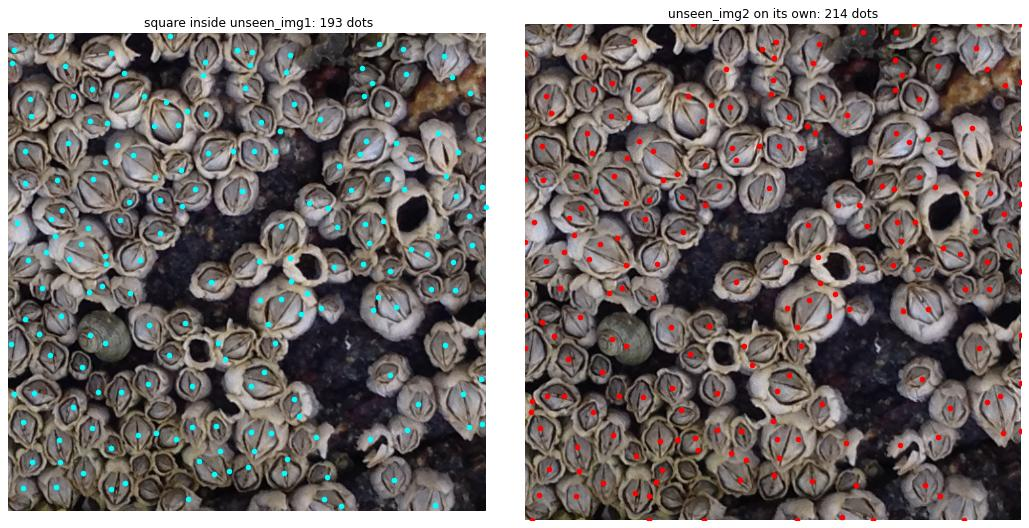

difference: +11%


In [23]:
raw = final["unseen_img1"]["dots_raw"]
box = (raw[:, 0] >= bx) & (raw[:, 0] < bx + 500) & (raw[:, 1] >= by) & (raw[:, 1] < by + 500)
inside = raw[box] - [bx, by]
fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))
axes[0].imshow(small); axes[0].scatter(inside[:, 0], inside[:, 1], s=16, c="cyan")
axes[0].set_title(f"square inside unseen_img1: {box.sum()} dots")
axes[1].imshow(small); axes[1].scatter(d2[:, 0], d2[:, 1], s=16, c="red")
axes[1].set_title(f"unseen_img2 on its own: {len(d2)} dots")
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()
print(f"difference: {100 * (len(d2) - box.sum()) / box.sum():+.0f}%")

The two agree within about 11%, and most of the extra standalone dots sit
along the borders. Some difference is expected: barnacles cut by
the square's border are counted when it stands alone, and kernels near an
image edge see less context.

**How much to trust 1,482?** Without labels, I can't measure it directly. The
held-out img1 results suggest an error of a few percent *if* unseen_img1
behaves like img1, which it visually resembles. The quickest real check would
be hand-counting one quarter of the crop.

## 12. Conclusions

**Is this approach worth pursuing?** For img1-like scenes, **yes**. A few
percent count error from simple, explainable tools and two labeled photos is a
solid first draft for human review. For very different scenes like img2,
**not yet**.

**How it fits the scientists' workflow:** the goal is to change their job from
*counting* 1,500 barnacles to *checking* 1,500 dots. A review tool would:

1. show the photo with dots;
2. let them click to add or remove dots;
3. highlight uncertain areas (tiles like section 9's, or probability near 0.5);
4. save the corrections as new point labels, which are far cheaper to make
   than traced outlines.

**What I'd do next, in order:**

1. **More labeled photos of varied scenes.** Every failure here is about
   scenes the model hasn't seen.
2. **The second-stage candidate judge** from section 10.
3. **Separate labels for live barnacles and empty shells.**

**What I deliberately didn't do:**

* **Deep learning.** With two labeled photos, a network would mostly memorize
  them; section 8 shows even a forest can't bridge two scenes.
* **Segment Anything.** Too slow without a GPU.
* **A rule for barnacles cut by the frame edge.** That should come from the
  scientists.

**What I learned:**

* **Look at the data before designing around it.** It was the lesson of
  nearly every section: outlines versus pockets, "green" versus teal, a scale
  problem that didn't exist. Each time, the fix came from zooming in on real
  pixels.
* **Preprocessing has hidden side effects.** Gap-closing fixed gaps but
  merged neighbors and erased small barnacles.
* **Evaluation design shapes the conclusion.** The same model looks terrible
  or good depending on the question asked, and both answers are true.

Full reasoning, dead ends, and sources: `LOG.md`.